# CLEARS — Exploratory Data Analysis (v3)
**File:** `notebooks/01_eda.ipynb`  |  **Author:** Person 1 — Data & Analytics Lead
**Dataset:** `data/processed/features_final.csv` — regenerated from the raw NOAA and BTS files (weather in correct local time, each flight once, leak-free rolling features); same 38 columns as the original delivery (`archive/original_delivery/features_final.csv`), see `docs/feature_dictionary.md`
**Airports:** ORD (Chicago O'Hare) | MEM (Memphis International)  |  **Period:** Jan 2019 – Oct 2022, **months Jan / Apr / Jul / Oct only**

This notebook replaces the original, whose plotting cells contained only a title comment (the code had not been saved). Every chart below is generated by the code in this notebook. Several statements in the original notebook were wrong and are corrected here (marked **corrected**).

## 1. Dataset overview

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
CANDIDATES = [Path('../data/processed/features_final.csv'), Path('data/processed/features_final.csv')]
DATA = next(p for p in CANDIDATES if p.exists())
ASSETS = Path('../assets') if Path('../assets').exists() else Path('assets')
ASSETS.mkdir(exist_ok=True)
COLORS = {'ORD': '#D85A30', 'MEM': '#1D9E75'}

df = pd.read_csv(DATA, low_memory=False, parse_dates=['timestamp', 'flight_date'])
print('File:', DATA.name, '| shape:', df.shape)
print('\nRecords per airport:\n', df['airport_code'].value_counts().to_string())
print('\nDate range:', df['flight_date'].min().date(), 'to', df['flight_date'].max().date())
print('Distinct dates with data:', df['flight_date'].nunique(), '(calendar span is',
      (df['flight_date'].max() - df['flight_date'].min()).days + 1, 'days)')
print('Months present:', sorted(df['month'].unique()))
print('\nOverall disruption rate: %.2f%%' % (df['disruption'].mean() * 100))
print('Null cells in the whole matrix:', int(df.isnull().sum().sum()))

File: features_final.csv | shape: (358594, 38)

Records per airport:
 airport_code
ORD    332108
MEM     26486

Date range: 2019-01-01 to 2022-10-31
Distinct dates with data: 492 (calendar span is 1400 days)
Months present: [1, 4, 7, 10]

Overall disruption rate: 17.85%
Null cells in the whole matrix: 0


**Key facts.** 358,594 flight departures (ORD 332,108; MEM 26,486). Data exists for only 492 distinct dates because BTS data was used for January, April, July and October only — about 35% of the calendar span, so results say little about November–December or the shoulder months. Zero null cells. (The original file had 370,729 rows: 12,135 of them were duplicated flights.)

## 2. Disruption rate by airport

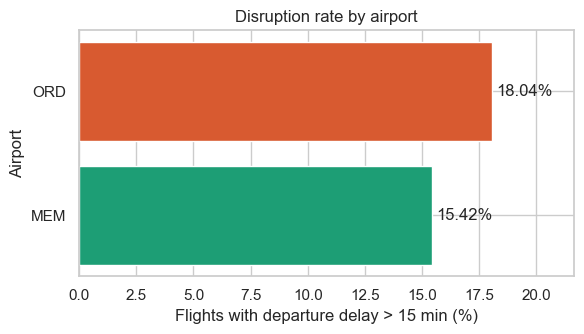

In [2]:
rate = df.groupby('airport_code')['disruption'].mean().mul(100).sort_values()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(rate.index, rate.values, color=[COLORS[a] for a in rate.index])
for y, v in enumerate(rate.values):
    ax.text(v + 0.2, y, f'{v:.2f}%', va='center')
ax.set_xlabel('Flights with departure delay > 15 min (%)')
ax.set_ylabel('Airport')
ax.set_title('Disruption rate by airport')
ax.set_xlim(0, rate.max() * 1.2)
plt.tight_layout(); plt.show()

**Finding.** ORD 18.04% vs MEM 15.42% (overall 17.85%). ORD has 332,108 flights vs 26,486 for MEM (**corrected** — the original text said 356,828). The class ratio is about 4.6 : 1, so `scale_pos_weight ≈ 4.6` is needed in XGBoost.

## 3. Distribution of weather variables

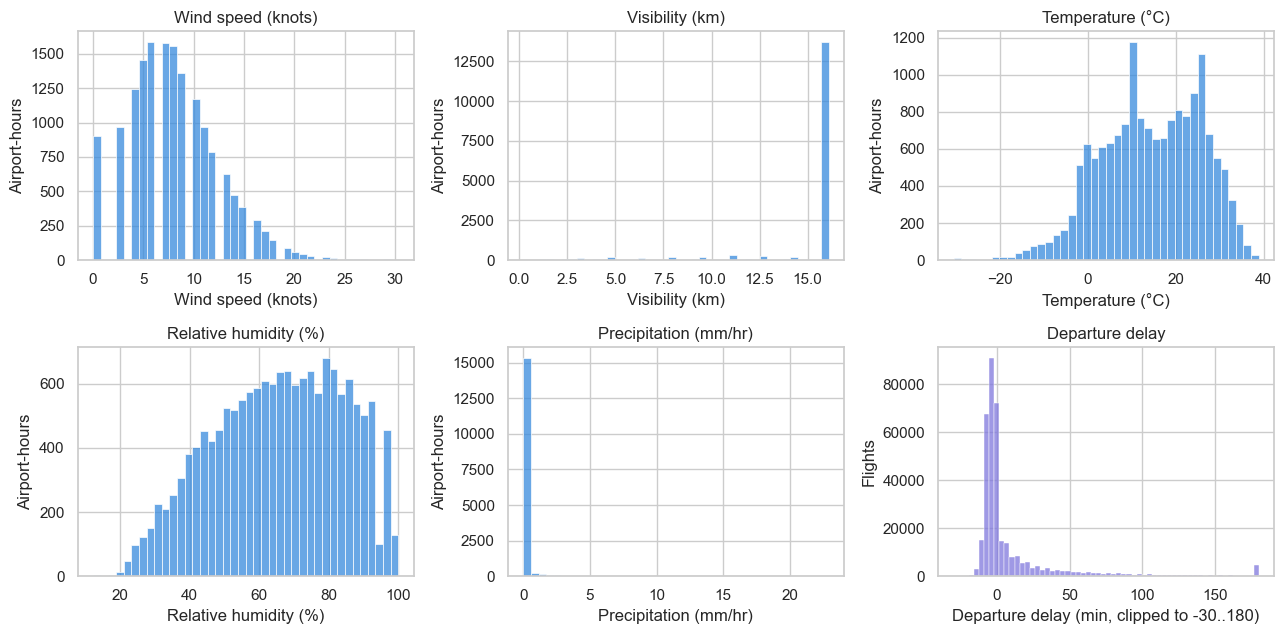

Max wind: 35.0 kn | visibility < 3 km: 1.83% of flights | no precipitation: 91.6% of flights


In [3]:
wx = df.drop_duplicates(['airport_code', 'timestamp'])      # one row per airport-hour, not per flight
panels = [('wind_speed_knots', 'Wind speed (knots)'), ('visibility_km', 'Visibility (km)'),
          ('temperature_c', 'Temperature (°C)'), ('humidity_pct', 'Relative humidity (%)'),
          ('precip_mm_hr', 'Precipitation (mm/hr)')]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (col, label) in zip(axes.ravel(), panels):
    sns.histplot(wx[col], bins=40, color='#378ADD', ax=ax)
    ax.set_xlabel(label); ax.set_ylabel('Airport-hours'); ax.set_title(label)
sns.histplot(df['dep_delay'].clip(-30, 180), bins=60, color='#7F77DD', ax=axes[1, 2])
axes[1, 2].set_xlabel('Departure delay (min, clipped to -30..180)'); axes[1, 2].set_ylabel('Flights')
axes[1, 2].set_title('Departure delay')
plt.tight_layout(); plt.show()
print('Max wind: %.1f kn | visibility < 3 km: %.2f%% of flights | no precipitation: %.1f%% of flights'
      % (df['wind_speed_knots'].max(), df['visibility_risk'].mean() * 100, (df['precip_mm_hr'] == 0).mean() * 100))

**Findings.** Wind is right-skewed and never exceeds 35 knots, so the `severe` wind category and the wind > 50 kn part of `storm_flag` never occur. Visibility is capped at 16.09 km (10 miles) with a small low-visibility tail. Precipitation is zero for ~92% of flights. Departure delay has a long right tail (capped at 300 for `delay_minutes`).

## 4. Disruption rate by hour of day

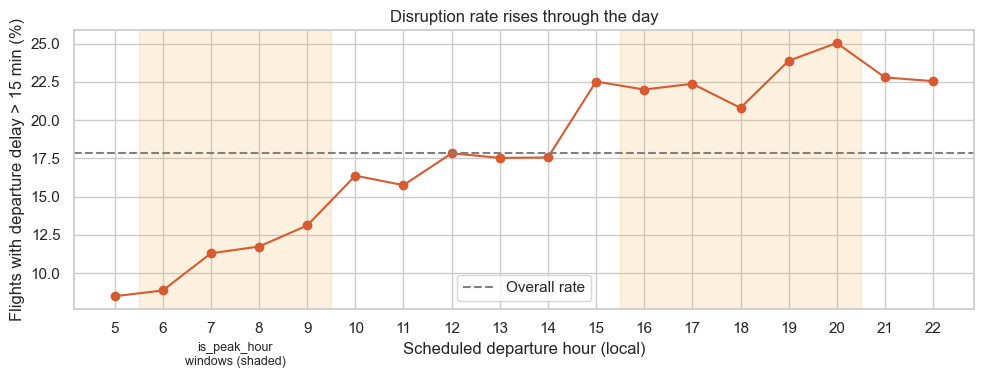

Disruption rate: peak 17.59% vs off-peak 18.20% (ratio 0.97)


In [4]:
hourly = df.groupby('hour_of_day')['disruption'].agg(['mean', 'size'])
hourly = hourly[hourly['size'] >= 500]              # hours 0, 1, 23 have too few flights to read
fig, ax = plt.subplots(figsize=(10, 4))
for a, b in [(6, 9), (16, 20)]:
    ax.axvspan(a - 0.5, b + 0.5, color='#EF9F27', alpha=0.15)
ax.plot(hourly.index, hourly['mean'] * 100, marker='o', color='#D85A30')
ax.axhline(df['disruption'].mean() * 100, ls='--', color='grey', label='Overall rate')
ax.text(7.5, 4, "is_peak_hour\nwindows (shaded)", ha='center', fontsize=9)
ax.set_xlabel('Scheduled departure hour (local)')
ax.set_ylabel('Flights with departure delay > 15 min (%)')
ax.set_title('Disruption rate rises through the day')
ax.set_xticks(hourly.index); ax.legend()
plt.tight_layout()
plt.savefig(ASSETS / 'eda_key_chart.png', dpi=150, bbox_inches='tight')    # key chart for the presentation
plt.show()
peak = df.groupby('is_peak_hour')['disruption'].mean() * 100
print('Disruption rate: peak %.2f%% vs off-peak %.2f%% (ratio %.2f)' % (peak[1], peak[0], peak[1] / peak[0]))

**Finding (corrected).** Disruption rises through the day — about 8.5% at 05:00, 16–18% around noon, and roughly 21–25% between 15:00 and 22:00 — consistent with delays accumulating and cascading. The `is_peak_hour` flag (06–09 and 16–20) does **not** capture this: peak 17.59% vs off-peak 18.20%, ratio ≈ 0.97, because 06–09 is the lowest-risk period. Use `hour_of_day`; `is_peak_hour` is not validated by the data (the original text claimed it was).

## 5. Disruption rate by day of week

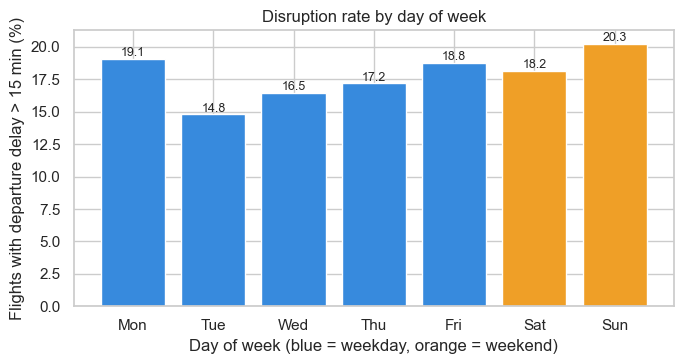

is_weekend
weekday    17.32
weekend    19.28


In [5]:
dow = df.groupby('day_of_week')['disruption'].mean().mul(100)
labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(labels, dow.values, color=['#378ADD'] * 5 + ['#EF9F27'] * 2)
for i, v in enumerate(dow.values):
    ax.text(i, v + 0.2, f'{v:.1f}', ha='center', fontsize=9)
ax.set_xlabel('Day of week (blue = weekday, orange = weekend)')
ax.set_ylabel('Flights with departure delay > 15 min (%)')
ax.set_title('Disruption rate by day of week')
plt.tight_layout(); plt.show()
print(df.groupby('is_weekend')['disruption'].mean().mul(100).round(2).rename({0: 'weekday', 1: 'weekend'}).to_string())

**Finding (corrected).** Sunday is highest (20.3%), then Monday (19.1%) and Friday (18.8%); Tuesday is lowest (14.8%). Weekends overall are *higher* than weekdays (19.3% vs 17.3%) — v1 said weekend disruption was lower.

## 6. Hour × day-of-week heatmap

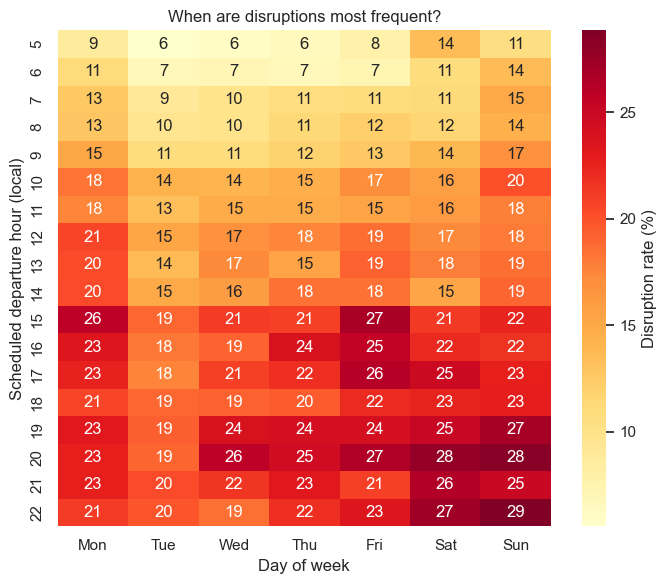

In [6]:
pivot = (df[df['hour_of_day'].between(5, 22)]
         .pivot_table(index='hour_of_day', columns='day_of_week', values='disruption', aggfunc='mean') * 100)
pivot.columns = labels
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd', cbar_kws={'label': 'Disruption rate (%)'}, ax=ax)
ax.set_xlabel('Day of week'); ax.set_ylabel('Scheduled departure hour (local)')
ax.set_title('When are disruptions most frequent?')
plt.tight_layout(); plt.show()

**Finding.** Late-afternoon and evening hours are the high-risk cells on every day of the week; early-morning departures are consistently the lowest.

## 7. Monthly disruption trend — ORD vs MEM

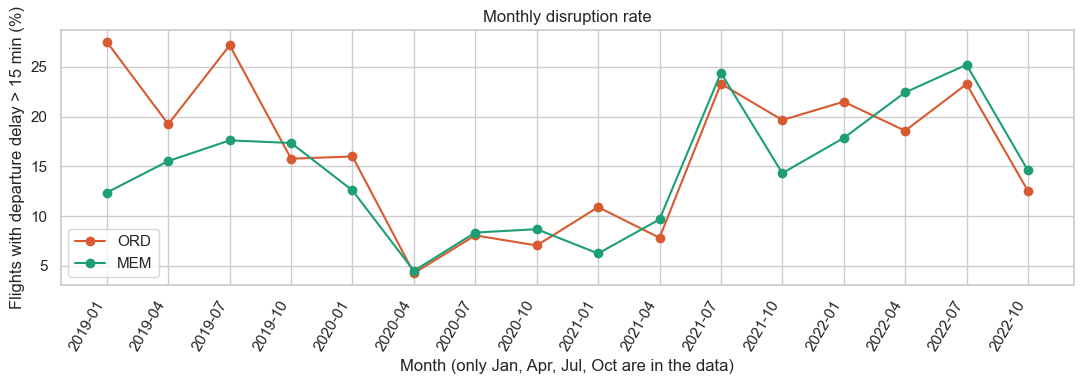

By year (%): {2019: 21.7, 2020: 10.5, 2021: 16.9, 2022: 19.0}
By month (%): {1: 19.4, 4: 14.8, 7: 22.0, 10: 14.7}


In [7]:
ym = (df.assign(period=df['flight_date'].dt.to_period('M').astype(str))
        .groupby(['period', 'airport_code'])['disruption'].mean().mul(100).unstack())
fig, ax = plt.subplots(figsize=(11, 4))
for a in ['ORD', 'MEM']:
    ax.plot(range(len(ym)), ym[a], marker='o', color=COLORS[a], label=a)
ax.set_xticks(range(len(ym))); ax.set_xticklabels(ym.index, rotation=60, ha='right')
ax.set_xlabel('Month (only Jan, Apr, Jul, Oct are in the data)')
ax.set_ylabel('Flights with departure delay > 15 min (%)')
ax.set_title('Monthly disruption rate'); ax.legend()
plt.tight_layout(); plt.show()
print('By year (%):', (df.groupby(df['flight_date'].dt.year)['disruption'].mean() * 100).round(1).to_dict())
print('By month (%):', (df.groupby('month')['disruption'].mean() * 100).round(1).to_dict())

**Findings.** July (22.0%) and January (19.4%) are the highest-risk months; April and October are about 14.8% and 14.7%. 2020 is an anomaly (10.5% vs 17–22% in other years — far fewer flights during COVID-19), so the model sees one very different regime. ORD is above MEM in only 7 of the 16 months, and **MEM is higher than ORD in all three months of the test period** (Apr 22.4% vs 18.6%, Jul 25.2% vs 23.3%, Oct 14.6% vs 12.5%). The airport ranking is not stable over time, which also weakens the ORD-vs-MEM resilience comparison.

## 8. Weather-event frequency by airport

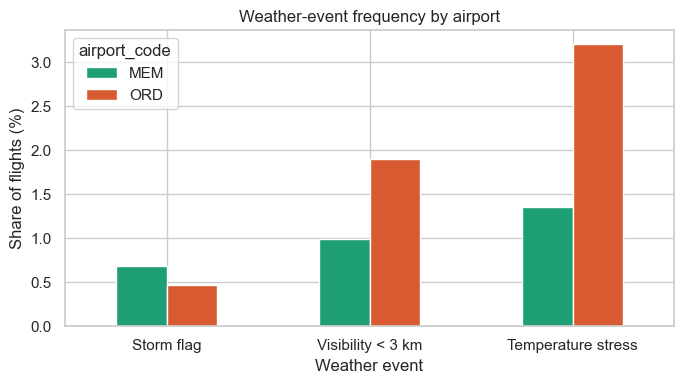

              Storm flag  Visibility < 3 km  Temperature stress
airport_code                                                   
MEM                 0.68               0.99                1.35
ORD                 0.47               1.90                3.20


In [8]:
events = (df.groupby('airport_code')[['storm_flag', 'visibility_risk', 'temp_stress']].mean().mul(100)
            .rename(columns={'storm_flag': 'Storm flag', 'visibility_risk': 'Visibility < 3 km',
                             'temp_stress': 'Temperature stress'}))
ax = events.T.plot.bar(figsize=(7, 4), color=[COLORS['MEM'], COLORS['ORD']], rot=0)
ax.set_xlabel('Weather event'); ax.set_ylabel('Share of flights (%)')
ax.set_title('Weather-event frequency by airport')
plt.tight_layout(); plt.show()
print(events.round(2).to_string())

**Finding (corrected).** ORD has more low-visibility flights (1.90% vs 0.99%) and far more temperature stress (3.2% vs 1.35%), but MEM has the *higher* storm-flag rate (0.68% vs 0.47%); the original text said ORD was higher on storm flag. Storm flag is rare (0.48% overall) and fires only on visibility < 1 km or heavy rain.

## 9. Correlation with disruption

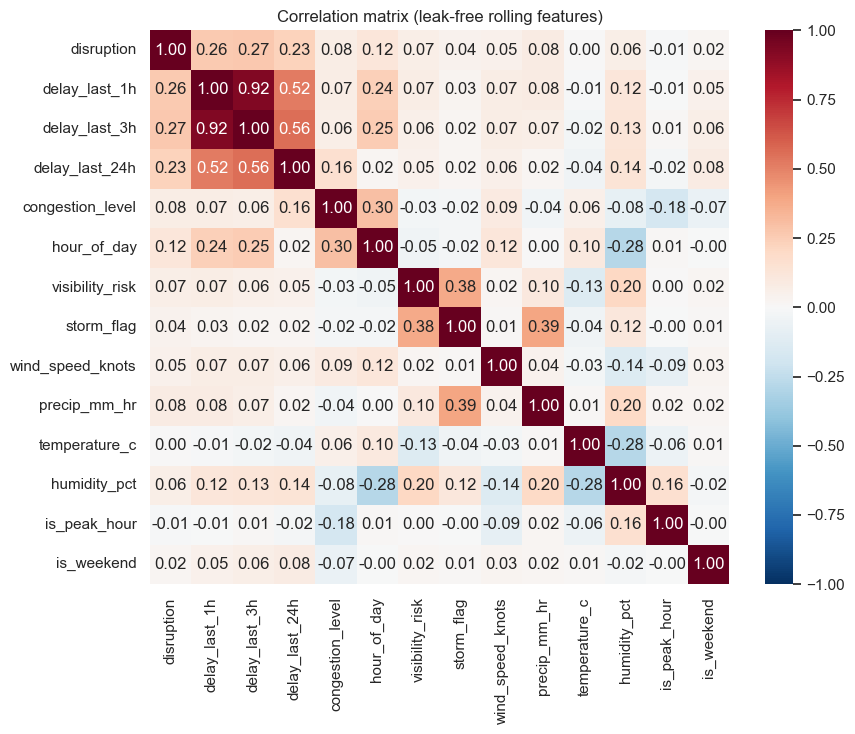

delay_last_3h       0.2670
delay_last_1h       0.2644
delay_last_24h      0.2271
hour_of_day         0.1195
precip_mm_hr        0.0824
congestion_level    0.0764
visibility_risk     0.0665
humidity_pct        0.0636
wind_speed_knots    0.0531
storm_flag          0.0434
is_weekend          0.0227
temperature_c       0.0012
is_peak_hour       -0.0079


In [9]:
cols = ['disruption', 'delay_last_1h', 'delay_last_3h', 'delay_last_24h', 'congestion_level', 'hour_of_day',
        'visibility_risk', 'storm_flag', 'wind_speed_knots', 'precip_mm_hr', 'temperature_c', 'humidity_pct',
        'is_peak_hour', 'is_weekend']
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation matrix (leak-free rolling features)')
plt.tight_layout(); plt.show()
print(corr['disruption'].drop('disruption').sort_values(ascending=False).round(4).to_string())

**Findings.** The strongest linear signals are the rolling disruption rates: `delay_last_3h` 0.267, `delay_last_1h` 0.264, `delay_last_24h` 0.227 — disruptions cascade. These are lower than the original values (0.347 / 0.302 / 0.254), which were inflated by outcomes of same-hour flights. `hour_of_day` (0.12) is next; precipitation 0.08, `visibility_risk` 0.07, wind 0.05 and `storm_flag` 0.04 are weak individually; `is_peak_hour` is ≈ 0. Single weather variables correlate below 0.09 with disruption, so the F1 ≥ 0.70 target is an open question, not an assumption.

## 10. Diagnostic: is the weather aligned with departure time?

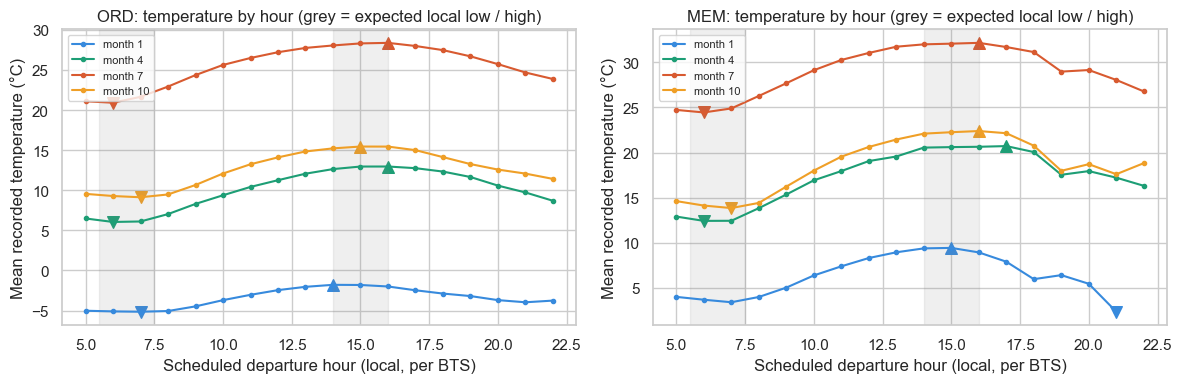

                    hour of lowest temperature  hour of highest temperature
airport_code month                                                         
MEM          1                              21                           15
             4                               6                           17
             7                               6                           16
             10                              7                           16
ORD          1                               7                           14
             4                               6                           16
             7                               6                           16
             10                              7                           15


In [10]:
wx = df.drop_duplicates(['airport_code', 'timestamp'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, a in zip(axes, ['ORD', 'MEM']):
    for m, c in zip([1, 4, 7, 10], ['#378ADD', '#1D9E75', '#D85A30', '#EF9F27']):
        s = wx[(wx['airport_code'] == a) & (wx['month'] == m) & wx['hour_of_day'].between(5, 22)]
        s = s.groupby('hour_of_day')['temperature_c'].mean()
        ax.plot(s.index, s.values, marker='o', ms=3, color=c, label=f'month {m}')
        ax.scatter([s.idxmin()], [s.min()], marker='v', s=70, color=c)
        ax.scatter([s.idxmax()], [s.max()], marker='^', s=70, color=c)
    ax.axvspan(5.5, 7.5, color='grey', alpha=0.12)
    ax.axvspan(14, 16, color='grey', alpha=0.12)
    ax.set_xlabel('Scheduled departure hour (local, per BTS)')
    ax.set_ylabel('Mean recorded temperature (°C)')
    ax.set_title(f'{a}: temperature by hour (grey = expected local low / high)')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
t = wx[wx['hour_of_day'].between(5, 22)].groupby(['airport_code', 'month', 'hour_of_day'])['temperature_c'].mean()
low = t.groupby(['airport_code', 'month']).idxmin().map(lambda i: i[2])
high = t.groupby(['airport_code', 'month']).idxmax().map(lambda i: i[2])
print(pd.DataFrame({'hour of lowest temperature': low, 'hour of highest temperature': high}).to_string())

**Finding.** With the weather matched in correct local time, mean temperature is lowest around 06–07 and highest around 16 in April, July and October, as expected; in January it warms from about 07 to a peak at 14 (a small winter amplitude, dominated by passing weather systems). The original file looked very different (lowest around hours 11–13, highest around 19–22) because NOAA's UTC times had been used as local times, making its weather 5–6 hours stale. This was verified directly against the raw files: the original temperature at hour *t* equals the correct local temperature 6 h earlier in January and 5 h earlier in the other months (correlation 0.9997–0.9999). See `docs/data_quality_report.md`, Check 8.

## 11. Key EDA conclusions (v3)

| Insight | Implication for the model |
|---|---|
| ORD 18.0% vs MEM 15.4% disruption; overall 17.85% (≈ 4.6 : 1) | Use `scale_pos_weight ≈ 4.6`; report metrics per airport |
| Rolling disruption rates are the strongest signals (corr ≈ 0.23–0.27, leak-free) | Keep them, use only the leak-free versions |
| Disruption rises through the day; `is_peak_hour` shows no premium (ratio 0.97) | Use `hour_of_day`; do not rely on `is_peak_hour` |
| July (22.0%) and January (19.4%) highest; April/October ≈ 14.7–14.8% | `month` is informative; `is_holiday_season` equals `month == 10` here (redundant) |
| Storm flag is rare (0.48%) and never fires on wind | Little signal from the flag itself; the raw weather columns carry the weather information |
| 2020 dip (10.5%), no winter month in the test period, MEM > ORD in the test months | Evaluate per airport and per month; test metrics will not cover winter |
| Weather, now correctly aligned, is clearly related to disruption in the raw data (visibility < 3 km: 36.5% disrupted vs 17.5%; heavy rain: 46%) but rare | Weather helps mainly through the rare severe events; delay history explains most of the rest |

**Overall.** The v3 dataset is usable for supervised learning: weather is aligned, flights are not duplicated and the rolling features are leak-free. Remaining limits: four months per year, two airports, cancelled flights removed, and modest signal in every feature group.